# Ledergor 2018 — 03 · Signatures → Gate 2 (module geography)
Read `manifold.h5ad`. Report the smoothed module geography and the pseudotime gradient, render the raw per-cell signature UMAPs (deliverables), and make the **Gate 2** call: a single pSom→Crest inverse gradient with Crest terminal is the non-branching GO.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); data_name = name[:-2] if name.endswith('-1') else name
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0], '| scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# gene-set overlaps (shared genes would inflate positive correlation; the inverse axis is not that)
G,P,C = [set(feat[x]) for x in ['GSE162534','GSE229103','rRNAModifications']]
print('overlap pSom&Crest =', len(P&C), '(small -> inverse axis is real, not a shared-gene artifact)')

cells: 8184 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 59/81 genes present
pSom: 67/98 genes present
Crest: 87/104 genes present
overlap pSom&Crest = 14 (small -> inverse axis is real, not a shared-gene artifact)


### Gate 2 — module geography
Smoothed spatial correlations and the pseudotime gradient. Crest terminal (high at large pseudotime, inverse to pSom) with no competing Gast/pSom arms is the non-branching pattern.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print()
print('GATE 2 -> GO (non-branching): single pSom->Crest inverse gradient, Crest terminal, Gast weak/flat;')
print('   pSom and Crest are the resolved programs, no competing Gast/pSom arms. Crest is terminal and')
print('   inverse to pSom (not enriched on a Gast arm) -> no Crest-arm inversion flag.')
print('GATE 3 -> NA: no bifurcation.')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.24
  Crest_sm vs Gast_sm: r = -0.28
  Crest_sm vs pSom_sm: r = -0.96
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.180
  pSom_sm: rho = -0.561
  Crest_sm: rho = +0.565
Neural-crest-high decile mean pseudotime = 0.81 (terminal if ~1)

GATE 2 -> GO (non-branching): single pSom->Crest inverse gradient, Crest terminal, Gast weak/flat;
   pSom and Crest are the resolved programs, no competing Gast/pSom arms. Crest is terminal and
   inverse to pSom (not enriched on a Gast arm) -> no Crest-arm inversion flag.
GATE 3 -> NA: no bifurcation.


### Signature UMAPs (deliverables) — raw per-cell scores
Raw `score_genes` values (not the smoothed field used for the geography read) on the house layout, one external colorbar each, matching the reference style.

<ipython-input-1-283b8fa9a20e>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
saved Gast_signature.pdf + colorbar
<ipython-input-1-283b8fa9a20e>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
saved pSom_signature.pdf + colorbar
<ipython-input-1-283b8fa9a20e>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
saved Crest_signature.pdf + colorbar


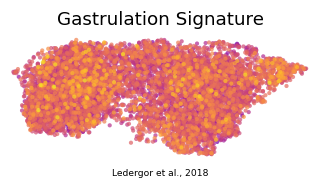

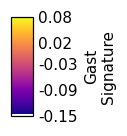

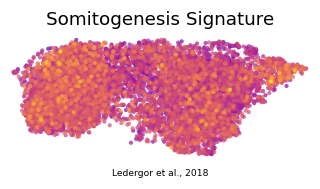

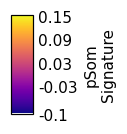

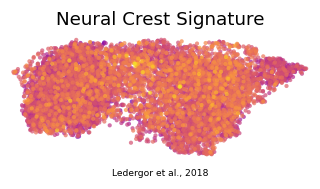

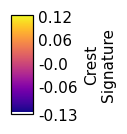

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Ledergor et al., 2018', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (8184, 24936)
